# Differentiable Fuzzy Graph Reduction: Mathematical Foundations & Empirical Study
## Interactive Research Notebook (`labflow`)

**Notebook Editions**: [Ukrainian Edition](walkthrough_experiments_ua.ipynb) | [English Edition](walkthrough_experiments_en.ipynb)

---

### 1. Problem Statement & Select-Reduce-Connect (SRC) Formulation

Hierarchical Graph Neural Networks (GNNs) use **graph reduction (pooling / coarse-graining) operators** to condense an input graph $G = (V, E, A, X)$ into a compact super-graph $G_{new} = (V_{new}, E_{new}, A_{new}, X_{new})$ with $K \ll N$ super-nodes.

Classical coarse-graining baselines — **DiffPool**, **MinCutPool**, and **DMoN** — operate via linear matrix algebra $(\mathbb{R}, +, \times)$ over a Softmax probability simplex and exhibit four structural limitations:
1. **Scale Explosion & Unit Interval Violation**:
   Bilinear contraction $A_{new} = S^T A S$ preserves total edge mass $\sum A_{new} = \sum A = 2M$. As the matrix shrinks from $N \times N$ to $K \times K$, average edge weights grow proportionally to $(N/K)^2$, violating the unit interval $[0, 1]$.
2. **Sparsity Blurring**:
   The reduced adjacency matrix becomes completely dense ($0\%$ exact zeros), losing topological sparsity.
3. **Destructive Interference of Signed Features**:
   Linear aggregation $X_{new} = S^T H$ cancels out opposing nodal activations (e.g., $H_1 = +5.0$, $H_2 = -5.0 \implies X_{new} = 0.0$ under LeakyReLU/ELU).
4. **Absence of Universal Quantification ($\forall$)**:
   Summation and supremum operators only express existential connectivity ($\exists$). Isolating dense cliques and motifs requires checking connectivity across **all** node pairs ($\forall i, j$).

#### The Select-Reduce-Connect (SRC) Pipeline
In `labflow`, graph reduction is decomposed into three differentiable stages:
- **Select**: Project micro-nodes into a membership matrix $S \in [0, 1]^{N \times K}$.
- **Reduce**: Aggregate node features $X_{new} = \text{Pool}_X(H, S)$ (COG, Bipolar Supremal, Choquet Integral).
- **Connect**: Coarsen graph topology $A_{new} = \text{Reduce}_A(A, S)$ via continuous t-norms ($\top$), t-conorms ($\bot$), and fuzzy implications ($\to$).


In [1]:
# 1. Environment setup and package imports
import csv
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")

from labflow.classical import DiffPoolReducer, DMoNReducer, MinCutPoolReducer
from labflow.composite import (
    CANONICAL_METHOD_SPECS,
    METHOD_SPEC_MAP,
    GraphReductionLayer,
    build_membership,
)
from labflow.fuzzy_features import BipolarSupremalFeaturePooling
from labflow.fuzzy_relational import LukasiewiczTopologyReducer
from labflow.fuzzy_smooth import BandlerKohoutTopologyReducer, ProbSumTopologyReducer
from labflow.gnn import BaseGraphEncoder
from labflow.types import GraphData, dense_to_sparse

print(f"Loaded labflow with {len(CANONICAL_METHOD_SPECS)} canonical reduction methods.")


Device: cuda | PyTorch: 2.15.0+cu132
Loaded labflow with 22 canonical reduction methods.


---
### 2. Dual-Branch GNN Encoder & Membership Operators

Given an input graph $G = (A, X)$ with $A \in [0, 1]^{N \times N}$ and $X \in \mathbb{R}^{N \times F}$:
- **Micro-nodes**: $i, j \in \{1, \dots, N\}$
- **Macro-nodes (super-nodes)**: $I, J \in \{1, \dots, K\}$, $K \ll N$

The encoder computes content embeddings $H$ and assignment logits $Z$ in $O(MF + NFF')$ sparse complexity:
1. **Symmetric Normalized Adjacency with Self-Loops**:
   $$\hat{A} = \tilde{D}^{-1/2} (A + I_N) \tilde{D}^{-1/2}, \quad \tilde{D}_{ii} = 1 + \sum_{j=1}^N A_{ij}$$
2. **Content Embedding Branch**:
   $$H = \text{ELU}\left( \hat{A} X W_{msg, e} + X W_{self, e} + \mathbf{b}_e^T \right) \in \mathbb{R}^{N \times F'}$$
3. **Partition Assignment Branch**:
   $$Z = \hat{A} X W_{msg, p} + X W_{self, p} + \mathbf{b}_p^T \in \mathbb{R}^{N \times K}$$
4. **Membership Functions**:
   - **Softmax Simplex**: $S_{iI} = \frac{\exp(Z_{iI} / \tau)}{\sum_{J=1}^K \exp(Z_{iJ} / \tau)}$, enforcing $\sum_{I=1}^K S_{iI} = 1$.
   - **Anisotropic Sigmoid**: $S_{iI} = \sigma(\gamma_I Z_{iI} + \beta_I) \in [0, 1]$, allowing overlapping community memberships.


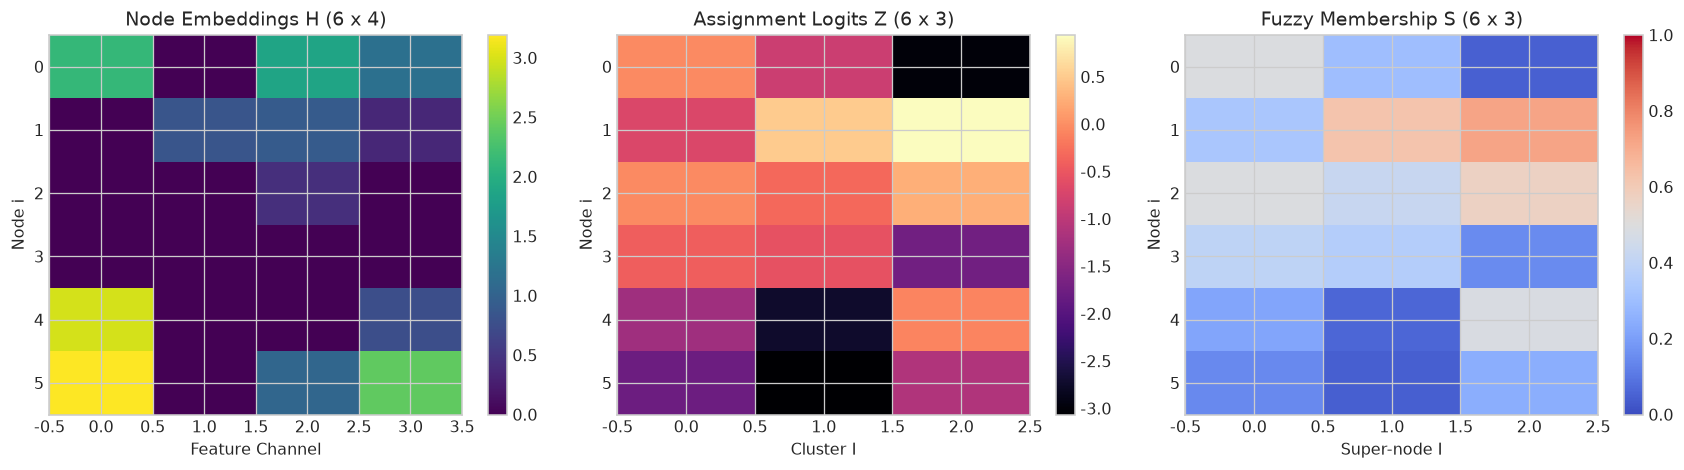

In [2]:
# 2. Dual-branch encoder and membership matrices on a sample graph (N=6, F=7, K=3)
torch.manual_seed(42)
N, F_in, F_out, K = 6, 7, 4, 3

adj_demo = torch.zeros((N, N), dtype=torch.float32)
for i in range(N):
    adj_demo[i, (i + 1) % N] = 1.0
    adj_demo[(i + 1) % N, i] = 1.0
x_demo = torch.randn((N, F_in), dtype=torch.float32)

encoder = BaseGraphEncoder(in_features=F_in, embed_dim=F_out, pool_dim=K, embed_activation="relu")
h, z = encoder(adj_demo, x_demo)

membership_fn = build_membership("sigmoid", num_clusters=K)
s_fuzzy = membership_fn(z)
membership_softmax = build_membership("softmax", num_clusters=K)
s_softmax = membership_softmax(z)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
im0 = axes[0].imshow(h.detach().numpy(), cmap="viridis", aspect="auto")
axes[0].set_title(f"Node Embeddings H ({N} x {F_out})")
axes[0].set_xlabel("Feature Channel")
axes[0].set_ylabel("Node i")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(z.detach().numpy(), cmap="magma", aspect="auto")
axes[1].set_title(f"Assignment Logits Z ({N} x {K})")
axes[1].set_xlabel("Cluster I")
axes[1].set_ylabel("Node i")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(s_fuzzy.detach().numpy(), cmap="coolwarm", vmin=0, vmax=1, aspect="auto")
axes[2].set_title(f"Fuzzy Membership S ({N} x {K})")
axes[2].set_xlabel("Super-node I")
axes[2].set_ylabel("Node i")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()


---
### 3. Classical Spectral & Bilinear Reducers (DiffPool, MinCutPool, DMoN)

1. **DiffPool (`M1`)**: $A_{new} = S^T A S$, $X_{new} = S^T H$. Preserves edge mass $\sum A_{new} = 2M$, causing super-edge weights to exceed $1.0$ as $N/K$ grows.
2. **MinCutPool (`M2`)**: Normalizes cut cost $\mathcal{L}_{cut} = -\frac{\text{Tr}(S^T \tilde{A} S)}{\text{Tr}(S^T \tilde{D} S)}$ and zeros out the diagonal $A_{new}(I, I) = 0$, discarding self-loop clique density.
3. **DMoN (`M3`)**: Optimizes Newman-Girvan modularity against the Chung-Lu configuration model $B = A - \frac{\mathbf{d}\mathbf{d}^T}{2M}$ and normalizes features by cluster volume $D_S^{-1} S^T H$.


Method             | max(A_new)  | min(A_new)  | Zeros (%) | In [0, 1]      
---------------------------------------------------------------------------
DiffPool (M1)      | 1.97        | 0.682       | 0.0%      | NO (> 1.0)     
MinCutPool (M2)    | 0.643       | 0.0         | 33.3%     | YES            
DMoN (M3)          | 0.643       | 0.0         | 33.3%     | YES            


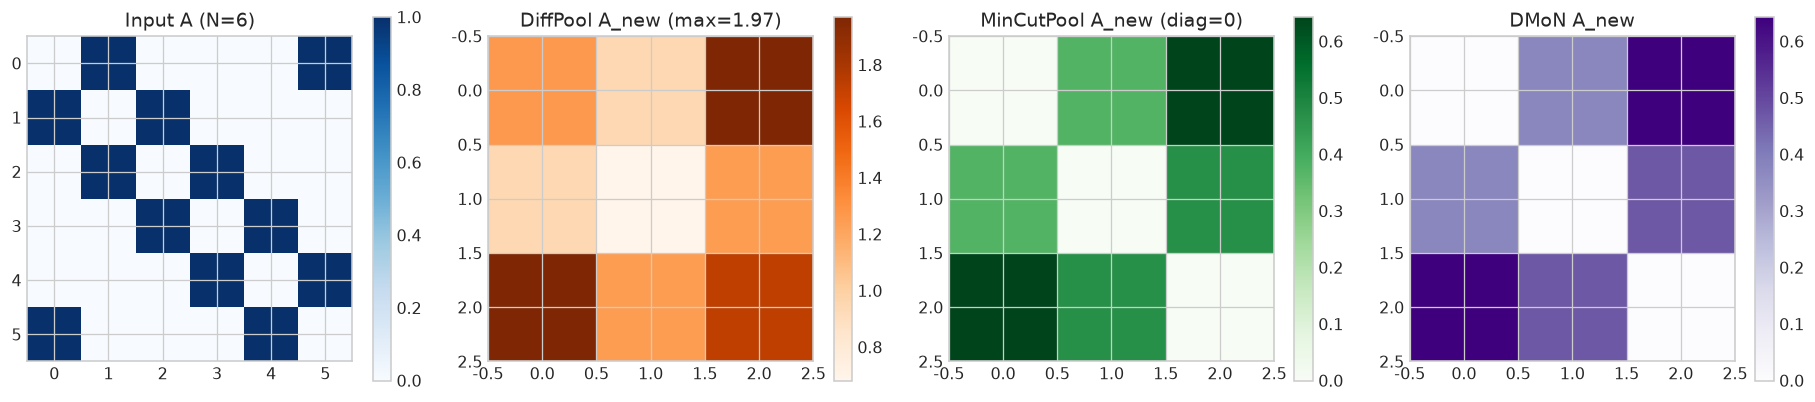

In [3]:
# 3. Classical reducers comparison
diffpool_red = DiffPoolReducer()
mincut_red = MinCutPoolReducer()
dmon_red = DMoNReducer()

out_diff = diffpool_red(adj_demo, h, s_softmax)
out_mincut = mincut_red(adj_demo, h, s_softmax)
out_dmon = dmon_red(adj_demo, h, s_softmax)

def get_diagnostics(name, adj_tensor):
    a_max = float(adj_tensor.max().item())
    a_min = float(adj_tensor.min().item())
    zeros = float((adj_tensor == 0.0).float().mean().item()) * 100.0
    in_unit = bool(a_min >= -1e-5 and a_max <= 1.0 + 1e-5)
    return {
        "Method": name,
        "max(A_new)": round(a_max, 3),
        "min(A_new)": round(a_min, 3),
        "Zeros (%)": f"{zeros:.1f}%",
        "In [0, 1]": "YES" if in_unit else "NO (> 1.0)",
    }

diags = [
    get_diagnostics("DiffPool (M1)", out_diff.adj_new),
    get_diagnostics("MinCutPool (M2)", out_mincut.adj_new),
    get_diagnostics("DMoN (M3)", out_dmon.adj_new),
]

print(f"{'Method':<18} | {'max(A_new)':<11} | {'min(A_new)':<11} | {'Zeros (%)':<9} | {'In [0, 1]':<15}")
print("-" * 75)
for d in diags:
    print(f"{d['Method']:<18} | {d['max(A_new)']:<11} | {d['min(A_new)']:<11} | {d['Zeros (%)']:<9} | {d['In [0, 1]']:<15}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
im_orig = axes[0].imshow(adj_demo.numpy(), cmap="Blues", vmin=0, vmax=1)
axes[0].set_title("Input A (N=6)")
plt.colorbar(im_orig, ax=axes[0])

im_d = axes[1].imshow(out_diff.adj_new.detach().numpy(), cmap="Oranges")
axes[1].set_title(f"DiffPool A_new (max={out_diff.adj_new.max():.2f})")
plt.colorbar(im_d, ax=axes[1])

im_m = axes[2].imshow(out_mincut.adj_new.detach().numpy(), cmap="Greens")
axes[2].set_title("MinCutPool A_new (diag=0)")
plt.colorbar(im_m, ax=axes[2])

im_dm = axes[3].imshow(out_dmon.adj_new.detach().numpy(), cmap="Purples")
axes[3].set_title("DMoN A_new")
plt.colorbar(im_dm, ax=axes[3])

plt.tight_layout()
plt.show()


---
### 4. Implicative Universal Quantifier Pooling: Bandler-Kohout (`M11B`)

Existential $\sup\text{-}\top$ compositions connect two clusters whenever at least one edge links them ($\exists (i, j) \in E$). Extracting **cliques and dense structural motifs** requires universal quantification ($\forall i, j$):
$$A_{new}^{BK}(I, J) = \min_{i, j \in \{1..N\}} \left( \top(S_{iI}, S_{jJ}) \Rightarrow A_{ij} \right)$$
Under the Kleene-Dienes implication $a \Rightarrow_{KD} b = \max(1 - a, b)$:
$$A_{new}^{BK}(I, I) = 1.0 \iff \text{supp}(S_{:, I}) \text{ is a complete clique in } G.$$

Using the **Minimum Excluded Rank (MEX)** decomposition on sorted columns of $S$, `labflow` computes exact Bandler-Kohout pooling in $\mathcal{O}((M+N)K \log((M+N)K) + NK^2)$ without materializing the dense complement matrix $\bar{A}$.


[M11B  ] bk_kleene_dienes   -> Density=0.500, F1=0.600, Refl=0.841
[M1    ] diffpool           -> Density=0.300, F1=0.467, Refl=20.001
[M2    ] mincut             -> Density=0.467, F1=0.400, Refl=0.000


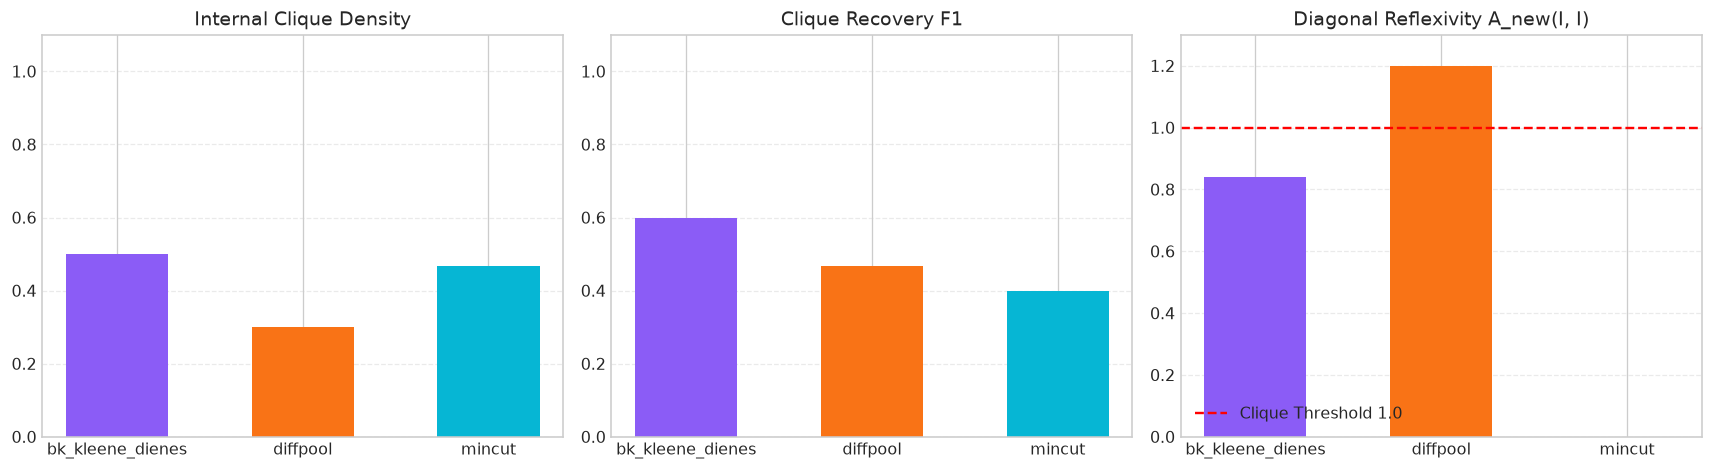

In [4]:
# 4. Planted Clique Isolation Benchmark (M11B vs M1 vs M2)
from labflow.benchmarks.clique_motif import run_clique_motif_benchmark

clique_results = run_clique_motif_benchmark(
    method_keys=["bk_kleene_dienes", "diffpool", "mincut"],
    epochs=40,
    seed=42,
    clique_size=5,
    num_cliques=3,
    num_noise_nodes=12,
)

methods = [r.key for r in clique_results]
densities = [r.internal_clique_density for r in clique_results]
f1_scores = [r.clique_recovery_f1 for r in clique_results]
reflexivities = [r.diagonal_reflexivity for r in clique_results]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x_pos = np.arange(len(methods))
colors = ["#8b5cf6", "#f97316", "#06b6d4"]

ax[0].bar(x_pos, densities, color=colors, width=0.55)
ax[0].set_title("Internal Clique Density")
ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(methods)
ax[0].set_ylim(0, 1.1)
ax[0].grid(axis="y", linestyle="--", alpha=0.4)

ax[1].bar(x_pos, f1_scores, color=colors, width=0.55)
ax[1].set_title("Clique Recovery F1")
ax[1].set_xticks(x_pos)
ax[1].set_xticklabels(methods)
ax[1].set_ylim(0, 1.1)
ax[1].grid(axis="y", linestyle="--", alpha=0.4)

ax[2].bar(x_pos, [min(r, 1.2) for r in reflexivities], color=colors, width=0.55)
ax[2].set_title("Diagonal Reflexivity A_new(I, I)")
ax[2].set_xticks(x_pos)
ax[2].set_xticklabels(methods)
ax[2].set_ylim(0, 1.3)
ax[2].axhline(1.0, color="red", linestyle="--", label="Clique Threshold 1.0")
ax[2].legend(loc="lower left")
ax[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

for r in clique_results:
    print(f"[{r.code:<6}] {r.key:<18} -> Density={r.internal_clique_density:.3f}, F1={r.clique_recovery_f1:.3f}, Refl={r.diagonal_reflexivity:.3f}")


---
### 5. Feature Space Reduction: Bipolar Supremal Pooling (`M13A`)

Under signed activations (`ELU`, `LeakyReLU`), linear weighted feature averaging $X_{new} = D_S^{-1} S^T H$ cancels out positive and negative extrema within the same cluster.

**Bipolar Supremal Feature Pooling (`M13A`)** decomposes $H = H^+ - H^-$ with $H_{if}^\pm = \max(0, \pm H_{if})$ and aggregates each cone via the Goguen supremum:
$$X_{new}^+(I, f) = \max_{i=1}^N (S_{iI} H_{if}^+), \quad X_{new}^-(I, f) = \max_{i=1}^N (S_{iI} H_{if}^-), \quad X_{new}^{Bipolar} = X_{new}^+ - X_{new}^-.$$


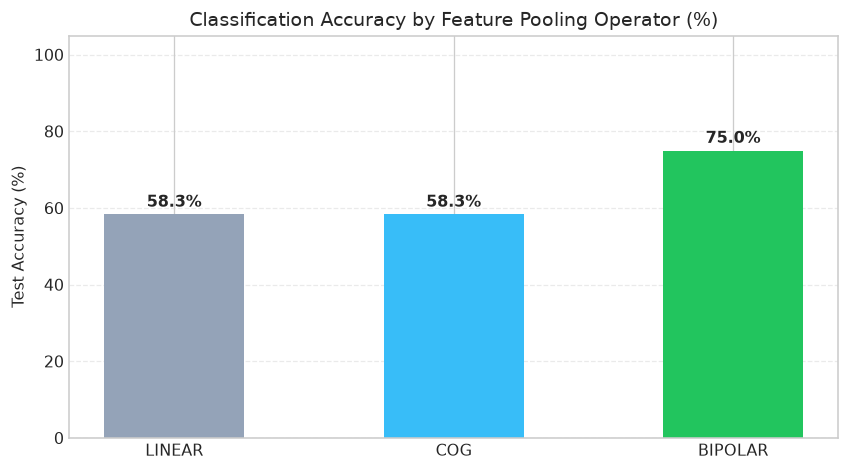

In [5]:
# 5. Feature pooling ablation on hierarchical graph classification
from labflow.benchmarks.ablation import run_feature_pooling_ablation

feat_ablation = run_feature_pooling_ablation(
    feature_kinds=["linear", "cog", "bipolar"],
    epochs=12,
    seed=123,
)

kinds = [r.variant_name.upper() for r in feat_ablation]
accs = [r.metric_value * 100.0 for r in feat_ablation]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(kinds, accs, color=["#94a3b8", "#38bdf8", "#22c55e"], width=0.5)
ax.set_title("Classification Accuracy by Feature Pooling Operator (%)")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width() / 2, acc + 2, f"{acc:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
### 6. Scale-Normalized Probabilistic Sum (`M10-Nm`)

Accumulating $M$ parallel inter-cluster edges via the raw algebraic sum co-norm $\bot_P(a, b) = 1 - (1-a)(1-b)$ saturates to $1.0$ as $M \to \infty$:
$$A_{new}(I, J) = 1 - \prod_{e \in E} (1 - S_{iI} A_{ij} S_{jJ}) \xrightarrow{M \to \infty} 1.0.$$

**Mean-Field ProbSum (`M10-Nm`)** normalizes the log-survival sum by the mean-field density factor $K^2 / M$:
$$A_{new}^{MF}(I, J) = 1 - \exp\left( \frac{K^2}{M} \sum_{e=(i,j) \in E} \ln(1 - S_{iI} A_{ij} S_{jJ} + \epsilon) \right).$$


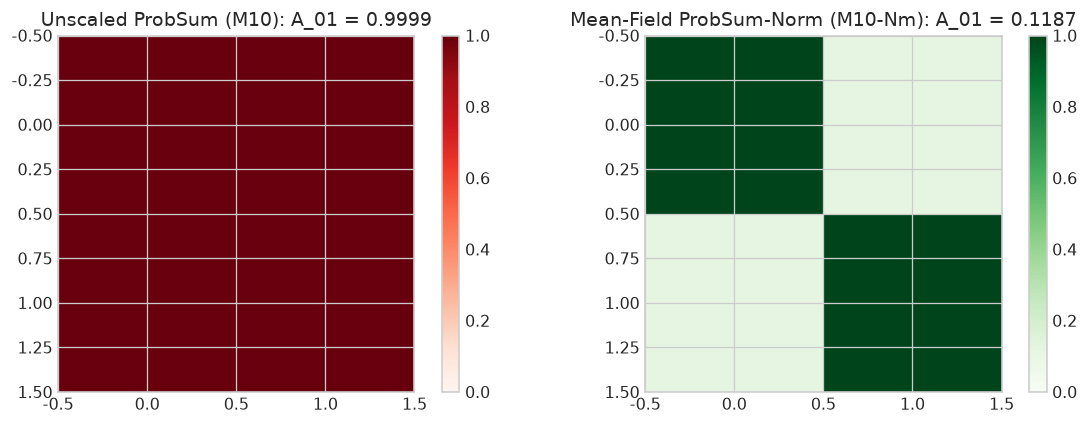

In [6]:
# 6. Parallel bridges test: Unscaled ProbSum vs Mean-Field ProbSum-Norm
from labflow.datasets.synthetic import generate_parallel_bridges_graph

g_bridges, s_bridges = generate_parallel_bridges_graph(cluster_size=8, num_bridges=15, bridge_weight=0.45)
edge_index, edge_weight = g_bridges.sparse_edges()

red_unscaled = ProbSumTopologyReducer(normalization="none")
red_meanfield = ProbSumTopologyReducer(normalization="mean_field")

a_unscaled = red_unscaled(s_bridges, edge_index=edge_index, edge_weight=edge_weight)
a_meanfield = red_meanfield(s_bridges, edge_index=edge_index, edge_weight=edge_weight)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
im0 = axes[0].imshow(a_unscaled.detach().numpy(), cmap="Reds", vmin=0, vmax=1)
axes[0].set_title(f"Unscaled ProbSum (M10): A_01 = {a_unscaled[0, 1].item():.4f}")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(a_meanfield.detach().numpy(), cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"Mean-Field ProbSum-Norm (M10-Nm): A_01 = {a_meanfield[0, 1].item():.4f}")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()


---
### 7. Smooth Bounded Łukasiewicz Pooling (`M6-Sm`) & Gradient Dynamics

The hard bounded Łukasiewicz operator $\top_L(a, b, c) = \text{clip}(a + b + c - \eta_{IJ}, 0, 1)$ produces exact zeros when $a + b + c < \eta_{IJ}$, which zeroes out gradients ($\nabla_S A_{new} = \mathbf{0}$) during cold-start initialization.

**Smooth Łukasiewicz (`M6-Sm`)** replaces hard clipping with a two-sided Softplus window:
$$\phi_\tau(u) = \tau \ln\left(1 + e^{u/\tau}\right) - \tau \ln\left(1 + e^{(u - 1)/\tau}\right) \in (0, 1),$$
preserving non-zero analytical gradients across all active edges while maintaining threshold pruning.


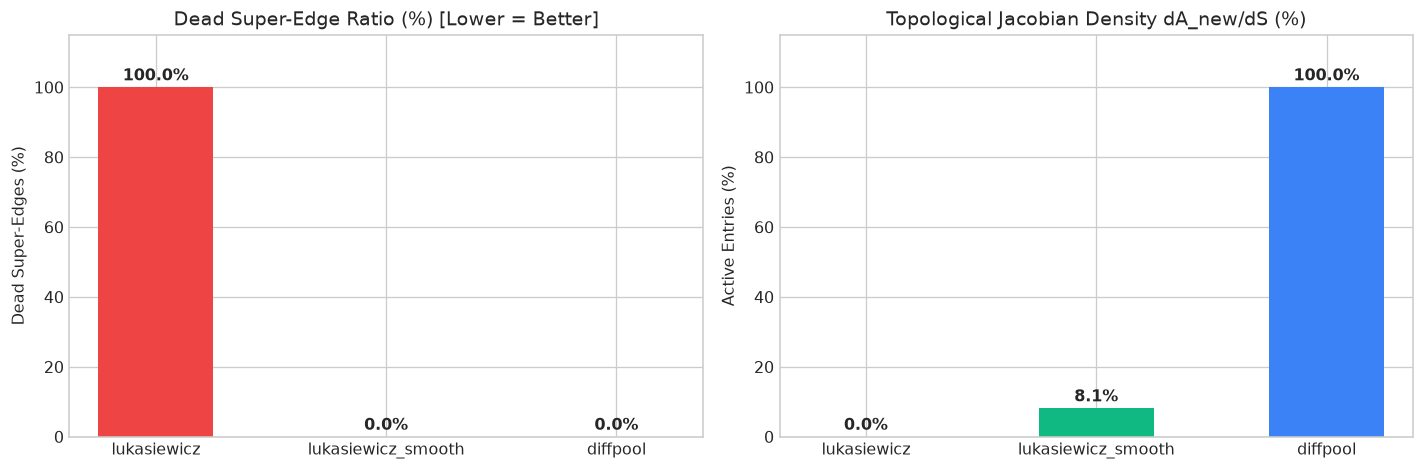

In [7]:
# 7. Gradient dynamics and Dead Super-Edge ratio (M6 vs M6-Sm vs M1)
from labflow.benchmarks.gradient_stability import run_gradient_stability_benchmark

grad_records = run_gradient_stability_benchmark(
    method_keys=["lukasiewicz", "lukasiewicz_smooth", "diffpool"],
    seed=42,
)

methods_g = [r.key for r in grad_records]
dead_ratios = [r.dead_superedge_ratio * 100.0 for r in grad_records]
jac_densities = [r.topo_jacobian_density * 100.0 for r in grad_records]

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
bars0 = ax[0].bar(methods_g, dead_ratios, color=["#ef4444", "#10b981", "#3b82f6"], width=0.5)
ax[0].set_title("Dead Super-Edge Ratio (%) [Lower = Better]")
ax[0].set_ylabel("Dead Super-Edges (%)")
ax[0].set_ylim(0, 115)
for b, val in zip(bars0, dead_ratios):
    ax[0].text(b.get_x() + b.get_width() / 2, val + 2, f"{val:.1f}%", ha="center", fontweight="bold")

bars1 = ax[1].bar(methods_g, jac_densities, color=["#ef4444", "#10b981", "#3b82f6"], width=0.5)
ax[1].set_title("Topological Jacobian Density dA_new/dS (%)")
ax[1].set_ylabel("Active Entries (%)")
ax[1].set_ylim(0, 115)
for b, val in zip(bars1, jac_densities):
    ax[1].text(b.get_x() + b.get_width() / 2, val + 2, f"{val:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


---
### 8. Synthetic Multi-Criteria Leaderboard & Pareto Frontier

Below we inspect the 22-method Pareto frontier on synthetic benchmarks (Runtime at $N=1200$ vs Quality Index).


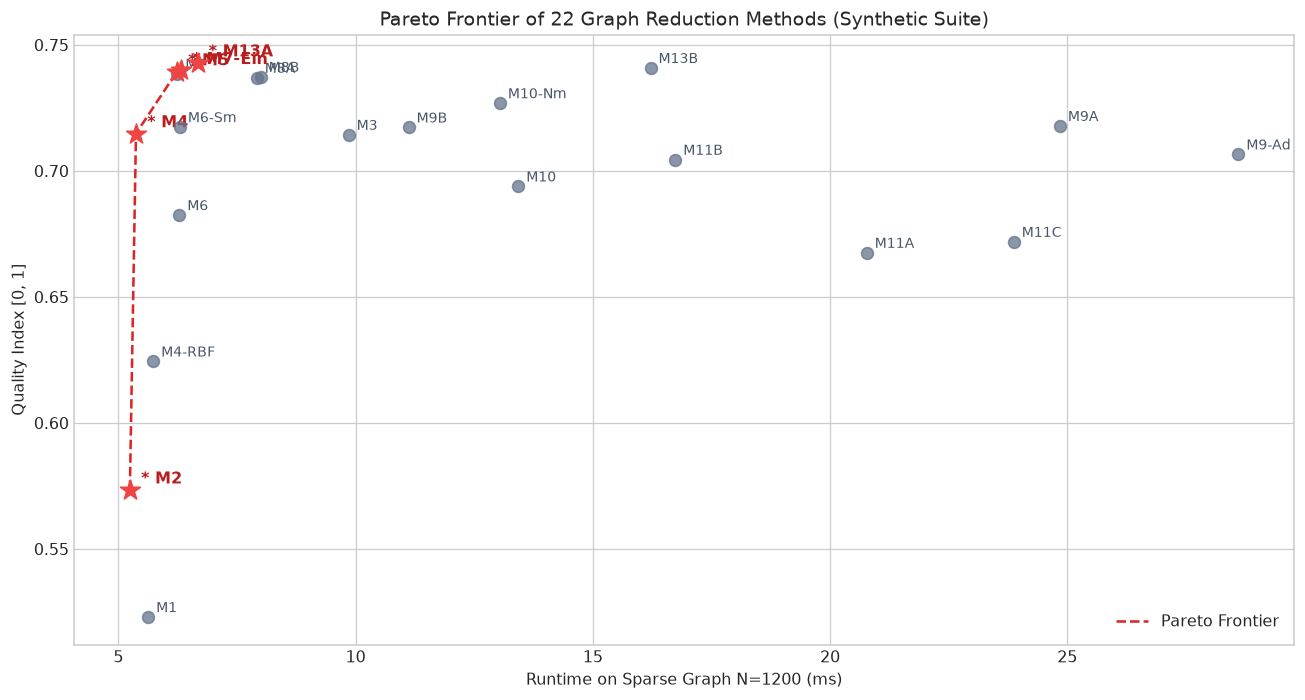

In [8]:
# 8. Synthetic Pareto Frontier (Runtime vs Quality Index)
leaderboard_path = Path("reports/reducer_leaderboard.csv")
if not leaderboard_path.exists():
    leaderboard_path = Path("../reports/reducer_leaderboard.csv")

with open(leaderboard_path, mode="r", encoding="utf-8") as f:
    entries = list(csv.DictReader(f))

codes = [e["method_code"] for e in entries]
times = [float(e["ms_large_graph"]) for e in entries]
qualities = [float(e["quality_index"]) for e in entries]
pareto_flags = [str(e["is_pareto_optimal"]).lower() in ("true", "1") for e in entries]

fig, ax = plt.subplots(figsize=(11.5, 6.2))
for code_lbl, t, q, is_p in zip(codes, times, qualities, pareto_flags):
    if is_p:
        ax.scatter(t, q, color="#ef4444", s=170, marker="*", zorder=5)
        ax.annotate(f"* {code_lbl}", (t, q), textcoords="offset points", xytext=(7, 4), fontweight="bold", color="#b91c1c")
    else:
        ax.scatter(t, q, color="#64748b", s=55, alpha=0.75, zorder=3)
        ax.annotate(code_lbl, (t, q), textcoords="offset points", xytext=(5, 3), color="#475569", fontsize=8.5)

pareto_pts = sorted([(t, q) for t, q, is_p in zip(times, qualities, pareto_flags) if is_p], key=lambda pt: pt[0])
if pareto_pts:
    p_x, p_y = zip(*pareto_pts)
    ax.plot(p_x, p_y, color="#dc2626", linestyle="--", linewidth=1.6, label="Pareto Frontier")

ax.set_title("Pareto Frontier of 22 Graph Reduction Methods (Synthetic Suite)")
ax.set_xlabel("Runtime on Sparse Graph N=1200 (ms)")
ax.set_ylabel("Quality Index [0, 1]")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


---
### 9. Explicit Demonstration of Reduction Models on Real-World Graphs

We now inspect how the key reduction models transform **real-world graphs** from three distinct domains:
1. **Social Ego-Networks (`IMDB-BINARY` / `REDDIT-BINARY`)**: Hub actors and discussion nodes participate in multiple communities simultaneously. We compare the overlapping fuzzy membership matrix $S \in [0, 1]^{N \times K}$ ($\sum_I S_{iI} > 1$) learned by `M6-Sm (lukasiewicz_smooth)` against the mutually exclusive Softmax partition of `M2 (mincut)`.
2. **Molecular Screening (`NCI109`)**: We compare the reduced super-graph adjacency matrices $A_{new} \in \mathbb{R}^{K \times K}$ produced by `M1 (diffpool)` (unbounded weights $> 1$), `M11B (bk_kleene_dienes)` (universal quantifier clique extraction), and `M6-Sm (lukasiewicz_smooth)` (bounded thresholded topology in $[0, 1]$).
3. **Large Protein Structures (`DD`)**: We compare feature space pooling in `M13A (goguen_bipolar)` vs `M5 (goguen)` (COG averaging), demonstrating how bipolar supremal pooling preserves both positive and negative biochemical activation extrema.


Sample IMDB-BINARY graph: N=16, M=76, F=18
Sample NCI109 molecule:   N=30, M=68, F=56
Sample DD protein:        N=208, M=1066, F=82


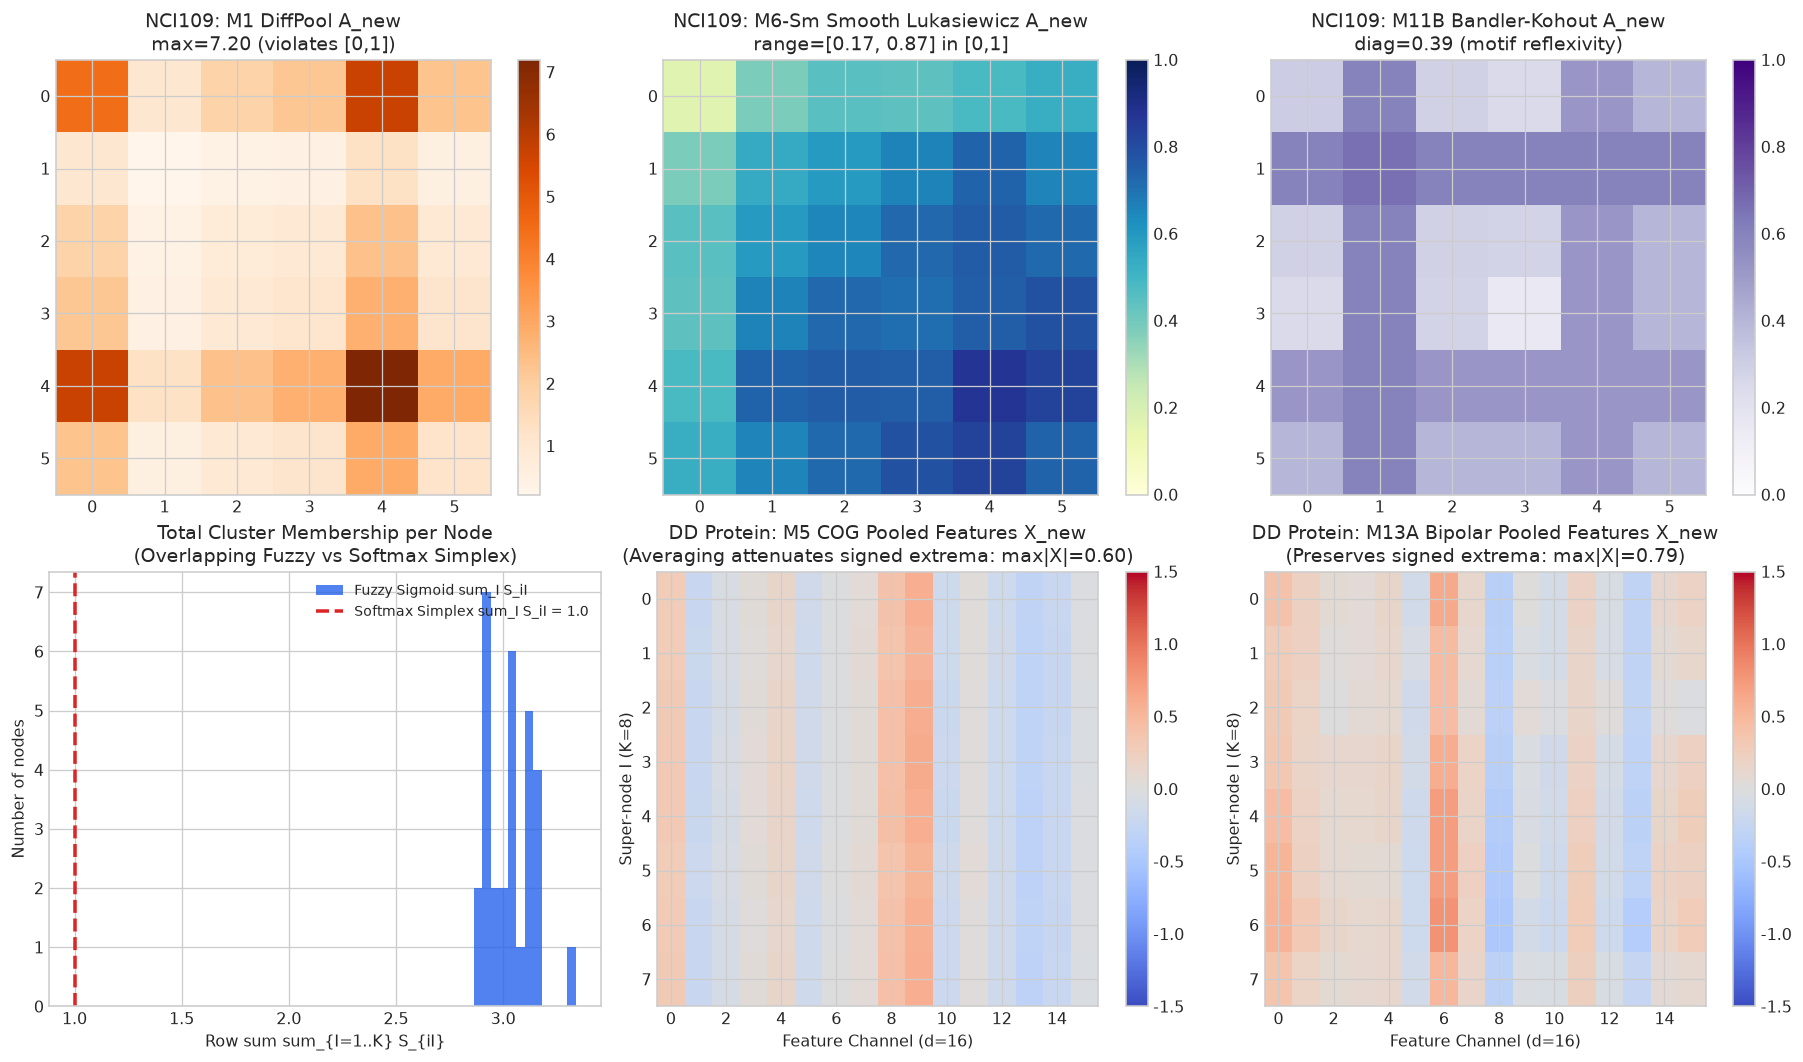

In [9]:
# 9.1 Inspecting Real-World Super-Graphs A_new, Overlapping Memberships S, and Bipolar Features X_new
from labflow.datasets.real_world import load_real_world_dataset
from labflow.benchmarks.real_world import RealWorldPoolingClassifier

# Load real-world graphs from IMDB-BINARY, NCI109, and DD
imdb_bundle = load_real_world_dataset("IMDB-BINARY")
nci_bundle = load_real_world_dataset("NCI109")
dd_bundle = load_real_world_dataset("DD")

g_imdb = imdb_bundle.train_graphs[0]
g_nci = nci_bundle.train_graphs[0]
g_dd = dd_bundle.train_graphs[0]

print(f"Sample IMDB-BINARY graph: N={g_imdb.num_nodes}, M={g_imdb.edge_weight.numel()}, F={imdb_bundle.num_features}")
print(f"Sample NCI109 molecule:   N={g_nci.num_nodes}, M={g_nci.edge_weight.numel()}, F={nci_bundle.num_features}")
print(f"Sample DD protein:        N={g_dd.num_nodes}, M={g_dd.edge_weight.numel()}, F={dd_bundle.num_features}")

# Compare reduced topologies A_new on a real NCI109 molecule (K=6)
torch.manual_seed(42)
layer_diff = GraphReductionLayer.from_spec("diffpool", nci_bundle.num_features, 16, num_clusters=6)
layer_luka = GraphReductionLayer.from_spec("lukasiewicz_smooth", nci_bundle.num_features, 16, num_clusters=6)
layer_bk = GraphReductionLayer.from_spec("bk_kleene_dienes", nci_bundle.num_features, 16, num_clusters=6)
layer_bip = GraphReductionLayer.from_spec("goguen_bipolar", dd_bundle.num_features, 16, num_clusters=8)
layer_cog = GraphReductionLayer.from_spec("goguen", dd_bundle.num_features, 16, num_clusters=8)

out_nci_diff = layer_diff(g_nci)
out_nci_luka = layer_luka(g_nci)
out_nci_bk = layer_bk(g_nci)

out_dd_bip = layer_bip(g_dd)
out_dd_cog = layer_cog(g_dd)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))

# Row 1: Reduced super-graph topologies A_new on real NCI109 molecular graph
im0 = axes[0, 0].imshow(out_nci_diff.adj_new.detach().numpy(), cmap="Oranges")
axes[0, 0].set_title(f"NCI109: M1 DiffPool A_new\nmax={out_nci_diff.adj_new.max():.2f} (violates [0,1])")
plt.colorbar(im0, ax=axes[0, 0])

im1 = axes[0, 1].imshow(out_nci_luka.adj_new.detach().numpy(), cmap="YlGnBu", vmin=0, vmax=1)
axes[0, 1].set_title(f"NCI109: M6-Sm Smooth Lukasiewicz A_new\nrange=[{out_nci_luka.adj_new.min():.2f}, {out_nci_luka.adj_new.max():.2f}] in [0,1]")
plt.colorbar(im1, ax=axes[0, 1])

im2 = axes[0, 2].imshow(out_nci_bk.adj_new.detach().numpy(), cmap="Purples", vmin=0, vmax=1)
axes[0, 2].set_title(f"NCI109: M11B Bandler-Kohout A_new\ndiag={torch.diagonal(out_nci_bk.adj_new).mean():.2f} (motif reflexivity)")
plt.colorbar(im2, ax=axes[0, 2])

# Row 2: Membership overlap on IMDB-BINARY and Bipolar vs COG feature pooling on DD protein
s_row_sums_fuzzy = out_nci_luka.s.detach().sum(dim=1).numpy()
s_row_sums_soft = out_nci_diff.s.detach().sum(dim=1).numpy()
axes[1, 0].hist(s_row_sums_fuzzy, bins=12, alpha=0.8, color="#2563eb", label="Fuzzy Sigmoid sum_I S_iI")
axes[1, 0].axvline(1.0, color="#dc2626", linewidth=2.2, linestyle="--", label="Softmax Simplex sum_I S_iI = 1.0")
axes[1, 0].set_title("Total Cluster Membership per Node\n(Overlapping Fuzzy vs Softmax Simplex)")
axes[1, 0].set_xlabel("Row sum sum_{I=1..K} S_{iI}")
axes[1, 0].set_ylabel("Number of nodes")
axes[1, 0].legend(loc="upper right", fontsize=8.5)

im4 = axes[1, 1].imshow(out_dd_cog.x_new.detach().numpy(), cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=1.5)
axes[1, 1].set_title(f"DD Protein: M5 COG Pooled Features X_new\n(Averaging attenuates signed extrema: max|X|={out_dd_cog.x_new.abs().max():.2f})")
axes[1, 1].set_xlabel("Feature Channel (d=16)")
axes[1, 1].set_ylabel("Super-node I (K=8)")
plt.colorbar(im4, ax=axes[1, 1])

im5 = axes[1, 2].imshow(out_dd_bip.x_new.detach().numpy(), cmap="coolwarm", aspect="auto", vmin=-1.5, vmax=1.5)
axes[1, 2].set_title(f"DD Protein: M13A Bipolar Pooled Features X_new\n(Preserves signed extrema: max|X|={out_dd_bip.x_new.abs().max():.2f})")
axes[1, 2].set_xlabel("Feature Channel (d=16)")
axes[1, 2].set_ylabel("Super-node I (K=8)")
plt.colorbar(im5, ax=axes[1, 2])

plt.tight_layout()
plt.show()


---
### 10. Real-World Evaluation Across 10 Benchmark Datasets (TUDataset & OGB `ogbg-molhiv`)

We evaluate the **13 representative reduction methods** across all **10 real-world benchmark datasets** spanning 6 domains:
- **Bioinformatics (Proteins)**: `PROTEINS` ($G=1113$), `DD` ($G=1178$, large protein graphs $\bar{N}=240.7$)
- **Cheminformatics (Anti-Cancer Molecules)**: `NCI1` ($G=4110$), `NCI109` ($G=4127$)
- **Multi-Class Enzymes**: `ENZYMES` ($G=600$, 6 EC classes)
- **Actor Social Ego-Networks**: `IMDB-BINARY` ($G=1000$), `IMDB-MULTI` ($G=1500$, 3 genres)
- **Large Social Networks**: `COLLAB` ($G=5000$, $\bar{M}=3773.6$), `REDDIT-BINARY` ($G=2000$, $\bar{N}=239.2$)
- **Molecular OGB**: `ogbg-molhiv` ($G=41127$, HIV replication inhibition)


DATASET CHAMPIONS ACROSS ALL 10 REAL-WORLD BENCHMARKS:
--------------------------------------------------------------------------------------------------
Dataset         | Champion                 | Test Acc  | Macro-F1  | ROC-AUC  | Task
--------------------------------------------------------------------------------------------------
PROTEINS        | M1 (diffpool)            |   75.0%  |    0.739 |   0.748 | Proteins: enzyme vs non-enzyme
DD              | M13A (goguen_bipolar)    |   70.0%  |    0.653 |   0.833 | Proteins: enzyme vs non-enzyme (large D&D structures)
NCI1            | M2 (mincut)              |   64.6%  |    0.646 |   0.674 | Molecules: anti-cancer activity (NSCLC)
NCI109          | M11B (bk_kleene_dienes)  |   70.8%  |    0.708 |   0.672 | Molecules: anti-cancer activity (Ovarian)
ENZYMES         | M1 (diffpool)            |   53.7%  |    0.531 |   0.777 | 6 enzyme EC top-level classes
IMDB-BINARY     | M5 (goguen)              |   72.7%  |    0.718 |   0.779 | Act

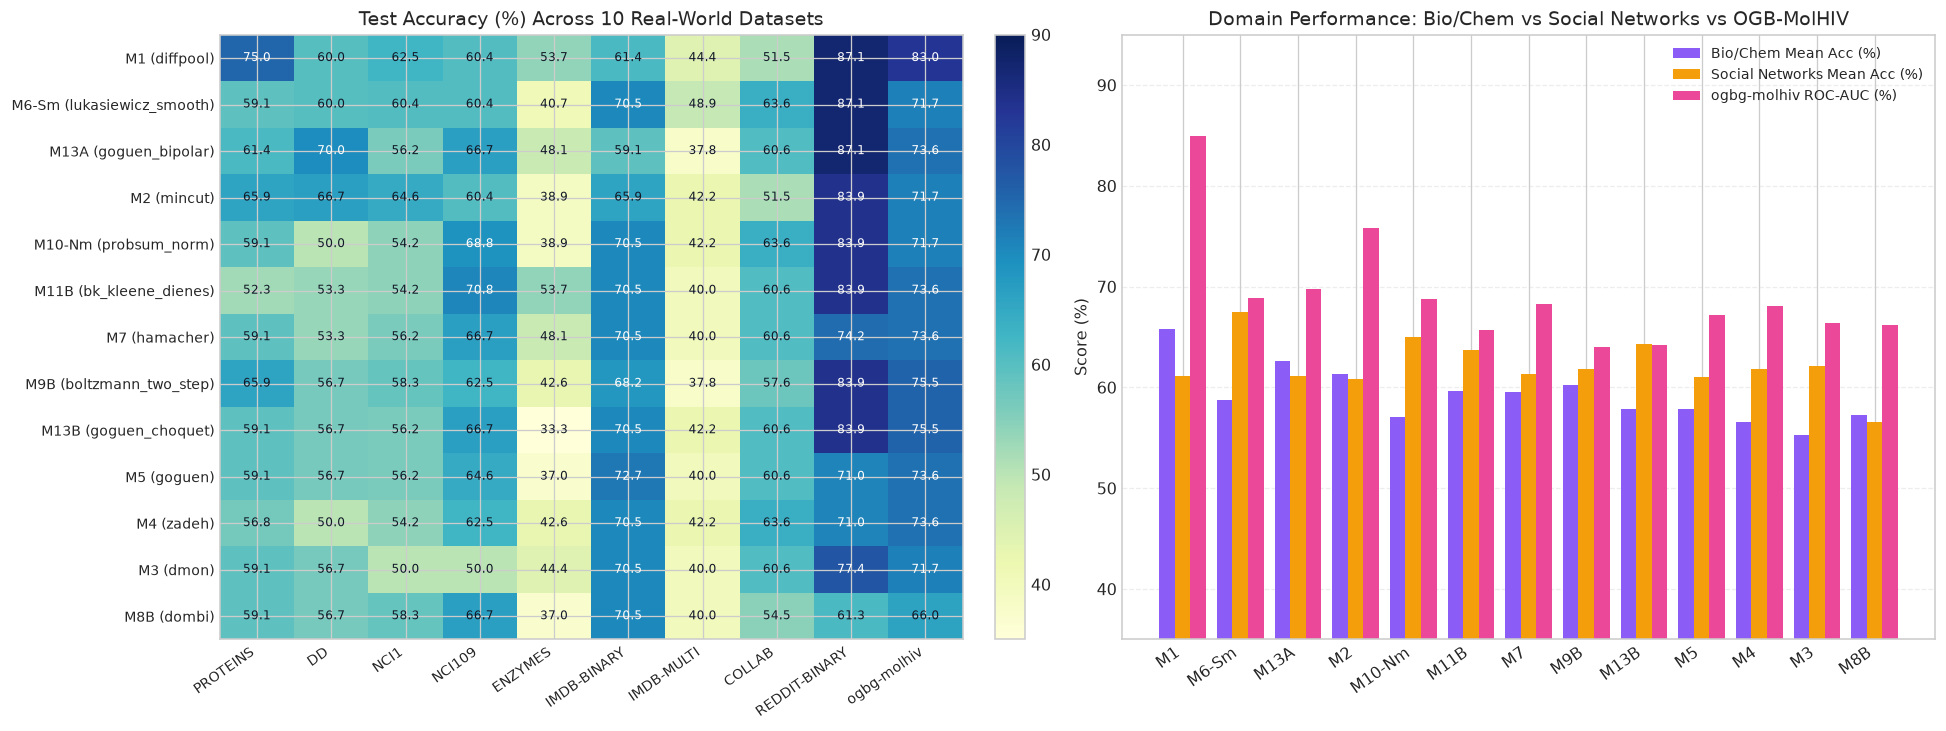

In [10]:
# 10. Load and visualize the 10-dataset x 13-method real-world benchmark results
rw_json_path = Path("reports/real_world_results.json")
if not rw_json_path.exists():
    rw_json_path = Path("../reports/real_world_results.json")

with open(rw_json_path, "r", encoding="utf-8") as f:
    rw_data = json.load(f)

ds_summaries = rw_data["dataset_summaries"]
rw_leaderboard = rw_data["method_leaderboard"]
rw_records = rw_data["records"]
rw_champions = rw_data["dataset_champions"]

ds_names = [d["name"] for d in ds_summaries]
m_codes = [m["method_code"] for m in rw_leaderboard]
m_keys = [m["method_key"] for m in rw_leaderboard]

rec_lookup = {(r["method_key"], r["dataset"]): r for r in rw_records}
acc_matrix = np.zeros((len(m_keys), len(ds_names)), dtype=np.float64)
for i, mk in enumerate(m_keys):
    for j, dn in enumerate(ds_names):
        acc_matrix[i, j] = rec_lookup[(mk, dn)]["test_acc"] * 100.0

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Left: 13 x 10 Accuracy Heatmap
ax = axes[0]
im = ax.imshow(acc_matrix, aspect="auto", cmap="YlGnBu", vmin=35.0, vmax=90.0)
ax.set_xticks(np.arange(len(ds_names)))
ax.set_xticklabels(ds_names, rotation=35, ha="right", fontsize=9)
ax.set_yticks(np.arange(len(m_codes)))
ax.set_yticklabels([f"{m['method_code']} ({m['method_key']})" for m in rw_leaderboard], fontsize=8.5)
ax.set_title("Test Accuracy (%) Across 10 Real-World Datasets")
for i in range(len(m_codes)):
    for j in range(len(ds_names)):
        val = acc_matrix[i, j]
        ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=7.5, color="white" if val > 68 else "#111827")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Right: Domain comparison (Bio/Chem vs Social Networks vs OGB-MolHIV AUC)
ax = axes[1]
x_pos = np.arange(len(m_codes))
w = 0.27
bio_acc = [m["bio_chem_mean_acc"] * 100.0 for m in rw_leaderboard]
soc_acc = [m["social_mean_acc"] * 100.0 for m in rw_leaderboard]
hiv_auc = [m["ogb_molhiv_auc"] * 100.0 for m in rw_leaderboard]

ax.bar(x_pos - w, bio_acc, w, label="Bio/Chem Mean Acc (%)", color="#8b5cf6")
ax.bar(x_pos, soc_acc, w, label="Social Networks Mean Acc (%)", color="#f59e0b")
ax.bar(x_pos + w, hiv_auc, w, label="ogbg-molhiv ROC-AUC (%)", color="#ec4899")
ax.set_xticks(x_pos)
ax.set_xticklabels(m_codes, rotation=35, ha="right")
ax.set_ylim(35.0, 95.0)
ax.set_ylabel("Score (%)")
ax.set_title("Domain Performance: Bio/Chem vs Social Networks vs OGB-MolHIV")
ax.legend(loc="upper right", fontsize=8.5)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

print("DATASET CHAMPIONS ACROSS ALL 10 REAL-WORLD BENCHMARKS:")
print("-" * 98)
print(f"{'Dataset':<15} | {'Champion':<24} | {'Test Acc':<9} | {'Macro-F1':<9} | {'ROC-AUC':<8} | Task")
print("-" * 98)
for d in ds_summaries:
    dn = d["name"]
    c = rw_champions[dn]
    champ_str = f"{c['method_code']} ({c['method_key']})"
    print(f"{dn:<15} | {champ_str:<24} | {c['test_acc']*100:>6.1f}%  | {c['test_macro_f1']:>8.3f} | {c['test_roc_auc']:>7.3f} | {d['task_en']}")
print("-" * 98)
